# Images and convolutional networks

In this notebook, we'll cover the use of convolutional neural networks for image classification.

If you are using Google Colab, you can enable GPUs for the notebook as follows:

- Navigate to Edit→Notebook Settings
- select GPU from the Hardware Accelerator drop-down

and restart the notebook.

By default, all operations in `keras` are run on GPU if a GPU is found.
If no GPU is available, the code runs on CPU without requiring any adaptation.

## LeNet and variants (shallow CNNs)

You will first experiments with rather shallow networks to get used to typical layers used in CNNs.


**Question 1.** Import the MNIST dataset and make sure it has the correct shape to feed a CNN (i.e. the dataset should 
have dimensions $(n, w, h, c)$ where $n$ is the number of images in the set, $w$ and $h$ are the width and height of an 
image and $c$ its number of channels: 1 for black & white images and 3 for RGB ones).

In [1]:
import os
# import torch 

# os.environ["KERAS_BACKEND"] = "torch"
# torch.set_default_device('cpu')

In [8]:
import keras
from keras.datasets import mnist
from keras.utils import to_categorical
import numpy as np

def prepare_mnist():
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
    x_train = x_train / 255.
    x_test = x_test / 255.
    x_train = x_train.reshape((-1, 28, 28, 1))
    x_test = x_test.reshape((-1, 28, 28, 1))

    # x_train = np.ascontiguousarray(x_train)
    # x_test = np.ascontiguousarray(x_test)
    
    y_train = to_categorical(y_train)
    y_test = to_categorical(y_test)
    return x_train, x_test, y_train, y_test

x_train, x_test, y_train, y_test = prepare_mnist()

In [3]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1), (60000, 10), (10000, 10))

To define a CNN, you will need (at least) the following layers:
* [`Conv2D`](https://keras.io/api/layers/convolution_layers/convolution2d/)
* [`MaxPooling2D`](https://keras.io/api/layers/pooling_layers/max_pooling2d/)
* [`Flatten`](https://keras.io/api/layers/reshaping_layers/flatten/)

**Question 2.** Implement a CNN with a single convolutional layer followed by a max-pooling and a fully-connected layer. Show the number of parameters of these networks and evaluate its performance on MNIST data.

In [4]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, InputLayer, Reshape

model = Sequential([
    InputLayer(shape=(28, 28, 1)),
    Conv2D(filters=11, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),
    Flatten(),
    Dense(units=10, activation="softmax")
])
# model.summary()

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(x_train, y_train, validation_data=(x_test, y_test),
          epochs=10, batch_size=200)

2025-11-10 16:28:30.137389: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Max
2025-11-10 16:28:30.137425: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-11-10 16:28:30.137431: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
2025-11-10 16:28:30.137508: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-11-10 16:28:30.137799: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/10


2025-11-10 16:28:30.508440: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7469 - loss: 1.0409 - val_accuracy: 0.9384 - val_loss: 0.2199
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9427 - loss: 0.2055 - val_accuracy: 0.9606 - val_loss: 0.1400
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9631 - loss: 0.1321 - val_accuracy: 0.9708 - val_loss: 0.1027
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9709 - loss: 0.1061 - val_accuracy: 0.9730 - val_loss: 0.0880
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9769 - loss: 0.0853 - val_accuracy: 0.9759 - val_loss: 0.0789
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9782 - loss: 0.0775 - val_accuracy: 0.9778 - val_loss: 0.0729
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9816 - loss: 0.0669 - val_accuracy: 0.9791 - val_loss: 0.0672
Epoch 8/10
 37/300 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9824 - loss: 0.0590

KeyboardInterrupt: 

**Question 3.** Implement the following network (leNet):

![leNet model](https://github.com/rtavenar/deep-notebooks/raw/main/assets/convnet_fig.svg)

Compare its performance to that of a fully connected model with the same number of parameters.

In [14]:
from keras.optimizers import Adam

model = Sequential([
    InputLayer(shape=(28, 28, 1)),
    Conv2D(filters=6, kernel_size=5, activation="relu"),
    MaxPooling2D(pool_size=2),
    Conv2D(filters=16, kernel_size=5, activation="relu"),
    MaxPooling2D(pool_size=2),
    Flatten(),
    Dense(units=120, activation="relu"),
    Dense(units=84, activation="relu"),
    Dense(units=10, activation="softmax")
])
model.summary()

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model.fit(x_train, y_train, validation_data=(x_test, y_test),
          epochs=10, batch_size=200)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.3260 - loss: 1.9923 - val_accuracy: 0.8634 - val_loss: 0.5294
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8694 - loss: 0.4722 - val_accuracy: 0.9088 - val_loss: 0.3105
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9063 - loss: 0.3210 - val_accuracy: 0.9251 - val_loss: 0.2532
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9224 - loss: 0.2654 - val_accuracy: 0.9353 - val_loss: 0.2132
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9309 - loss: 0.2297 - val_accuracy: 0.9438 - val_loss: 0.1855
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9404 - loss: 0.2012 - val_accuracy: 0.9501 - val_loss: 0.1659
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9474 - loss: 0.1769 - val_accuracy: 0.9541 - val_loss: 0.1480
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9517 - loss: 0.1612 - val_accu

## Image classification with ResNet models

A very efficient way to perform real-world image classification is to rely on a pretrained model.
`keras` provides models trained on ImageNet.
In this section, you will use `ResNet50` to classify images you will provide.

**Question 4.** Adapt the following code (that comes from [`keras` docs](https://keras.io/applications/#usage-examples-for-image-classification-models)) to classify a kangaroo image that you will first upload in the notebook files.

In [16]:
from keras.applications.resnet50 import ResNet50
from keras.preprocessing import image
from keras.applications.resnet50 import preprocess_input, decode_predictions
import numpy as np

model = ResNet50(weights='imagenet')

img_path = 'kangaroo.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x_input = preprocess_input(x)

preds = model.predict(x_input)
# decode the results into a list of tuples (class, description, probability)
# (one such list for each sample in the batch)
print('Predicted:', decode_predictions(preds, top=3)[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted: [('n02437312', 'Arabian_camel', 0.9710915), ('n01877812', 'wallaby', 0.018139174), ('n02437616', 'llama', 0.002741548)]


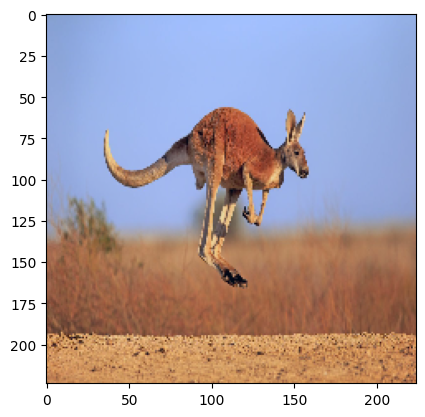

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.imshow((x[0] - x.min()) / (x.max() - x.min()));

## Fine-tuning a model to your data

Very often, however, your image classification problem will not match ImageNet classes.
In such cases, a typical strategy consists in fine-tuning an existing model to your problem.
This is done by learning only the fully connected layers at the ouput of the model and keep other layers freezed.

When loading weights from a pretrained model, `keras` offers an option to remove the classification layers and freeze weights of the convolutional layers:

```python
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=x_train.shape[1:])
for layer in base_model.layers:
  layer.trainable = False
```

Note that here, we provide the image shape when re-building the `ResNet50` model so that, if that shape is not the one of ImageNet images, `keras` will still be able to compute all tensor shapes in the network automatically.

From that point, `base_model` can be used in a `Sequential` model as if it were a single layer, which makes it feasible to plug new layers at the output of the `ResNet50` convolutions.

### The dataset

In this notebook, you will work with a new dataset that cannot be loaded via `keras.datasets` module.
Execute the commands below to download and extract the dataset:

In [17]:
!wget https://github.com/rtavenar/ml-datasets/releases/download/cats_and_dogs/cats_and_dogs.zip && unzip cats_and_dogs.zip

--2025-11-10 16:53:17--  https://github.com/rtavenar/ml-datasets/releases/download/cats_and_dogs/cats_and_dogs.zip
Résolution de github.com (github.com)… 140.82.121.3
Connexion à github.com (github.com)|140.82.121.3|:443… connecté.
requête HTTP transmise, en attente de la réponse… 302 Found
Emplacement : https://release-assets.githubusercontent.com/github-production-release-asset/752757641/e5db403f-8d7b-42ae-8d7d-4ec57e49ddfc?sp=r&sv=2018-11-09&sr=b&spr=https&se=2025-11-10T16%3A37%3A54Z&rscd=attachment%3B+filename%3Dcats_and_dogs.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2025-11-10T15%3A37%3A02Z&ske=2025-11-10T16%3A37%3A54Z&sks=b&skv=2018-11-09&sig=0Ahvnjm7IU2XDIMuZfQ1UlF4AoUjH3Ww1z0xTM7LhCI%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc2Mjc5MTc5NywibmJmIjoxNzYyNzg5OTk3LCJwYXRoIjoicmVsZWFzZWF

OSError: [Errno 5] Input/output error

Now, whatever your platform, run the cells below:

In [18]:
folder_data = "./cats_and_dogs/"

In [19]:
!ls './cats_and_dogs/'

test_catdog  train_catdog


The last line of the output above should be:
```
test_catdog  train_catdog
```

Then the data should be loaded using the following functions:

In [20]:
import os

folder_data = './cats_and_dogs/'
def load_cats_and_dogs_folder(path, target_size=None, verbose=True):
    X = []
    y = []
    i = 0
    for fname in os.listdir(path):
        if 'cat' in fname:
            X.append(
                np.array(image.load_img(path+fname, target_size=target_size))
            )
            y.append(0)
        elif 'dog' in fname:
            X.append(
                np.array(image.load_img(path+fname, target_size=target_size))
            )
            y.append(1)
        i+=1
        if verbose and i % 50 == 0:
            print('{0:.2f} % loaded'.format(100*(i/len(os.listdir(path)))))
    return np.array(X), np.array(y)

def load_preprocessed_cats_and_dogs(base_folder, target_size=None, 
                                    verbose=True):
    if verbose:
        print("Loading training set")
    X_train, y_train = load_cats_and_dogs_folder(base_folder + "/train_catdog/", 
                                                 target_size=target_size,
                                                 verbose=verbose)
    X_train = preprocess_input(X_train)

    if verbose:
        print("Loading test set")
    X_test, y_test = load_cats_and_dogs_folder(base_folder + "/test_catdog/", 
                                               target_size=target_size,
                                               verbose=verbose)
    X_test = preprocess_input(X_test)

    return X_train, X_test, y_train, y_test

# The call is here:
X_train, X_test, y_train, y_test = load_preprocessed_cats_and_dogs(folder_data, target_size=(200, 200))

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape) 

Loading training set
9.96 % loaded
19.92 % loaded
29.88 % loaded
39.84 % loaded
49.80 % loaded
59.76 % loaded
69.72 % loaded
79.68 % loaded
89.64 % loaded
99.60 % loaded
Loading test set
10.00 % loaded
20.00 % loaded
30.00 % loaded
40.00 % loaded
50.00 % loaded
60.00 % loaded
70.00 % loaded
80.00 % loaded
90.00 % loaded
100.00 % loaded
(502, 200, 200, 3) (502,) (500, 200, 200, 3) (500,)


### The model

**Question 5.** Now you will:

1. use convolution layers from a pre-trained `ResNet50` model and freeze them;
2. plug an additional logistic regression layer;
3. compile the full model;
4. observe the performance of such a model on your Cat vs Dog problem.

**Question 6.** Starting from the model you got at the previous stage, fine-tune _all_ the weights in this model
(even the convolution ones) using a learning rate of .00001 (1e-5). See if this improves on performance.

**Question 7.** Compare performance of this fine-tuned model with that of a shallow CNN model that you would define and train from scratch.